In [1]:
import pytest
import ipytest
ipytest.autoconfig()

In [2]:
import pandas as pd


In [3]:
week = pd.DataFrame({
    "day" : ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"],
    "temp" : [28, 31, 34, 29, 30, 26, 32],
    "rain_mm" : [0, 2, 0, 5, 1, 8, 0],
    "sky" : ["sun", "cloud", "sun", "rain", "cloud", "rain", "sun"],
})

week

,day,temp,rain_mm,sky
0,Mon,28,0,sun
1,Tue,31,2,cloud
2,Wed,34,0,sun
3,Thu,29,5,rain
4,Fri,30,1,cloud
5,Sat,26,8,rain
6,Sun,32,0,sun


In [4]:
week.head(2)

,day,temp,rain_mm,sky
0,Mon,28,0,sun
1,Tue,31,2,cloud


In [5]:
week.tail(2)

,day,temp,rain_mm,sky
5,Sat,26,8,rain
6,Sun,32,0,sun


In [6]:
week.shape

(7, 4)

In [7]:
week.info()

<class 'pandas.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   day      7 non-null      str  
 1   temp     7 non-null      int64
 2   rain_mm  7 non-null      int64
 3   sky      7 non-null      str  
dtypes: int64(2), str(2)
memory usage: 356.0 bytes


In [8]:
week.dtypes

day          str
temp       int64
rain_mm    int64
sky          str
dtype: object

In [9]:
week["rain_mm"]

0    0
1    2
2    0
3    5
4    1
5    8
6    0
Name: rain_mm, dtype: int64

In [10]:
type(week["rain_mm"])

pandas.Series

In [11]:
type(week)

pandas.DataFrame

In [12]:
week["rain_mm"] = week["rain_mm"].astype(float)

In [13]:
week["rain_mm"]

0    0.0
1    2.0
2    0.0
3    5.0
4    1.0
5    8.0
6    0.0
Name: rain_mm, dtype: float64

In [14]:
week.to_csv("week.csv", index=False)

To read a csv file in python we do 
`` df = pd.read_csv("week.csv") ``
`` df.head(2) ``


In [15]:
df = pd.read_csv("week.csv")

In [16]:
df["rain_mm"].mean()

np.float64(2.2857142857142856)

In [17]:
print(f"The median rain in mm is {df['rain_mm'].median()}")
print(df["rain_mm"].median())
print(df["rain_mm"].max())
print(df["rain_mm"].min())
print(df["rain_mm"].sum())

The median rain in mm is 1.0
1.0
8.0
0.0
16.0


In [18]:
df["sky"].unique()

<StringArray>
['sun', 'cloud', 'rain']
Length: 3, dtype: str

In [19]:
df["sky"].value_counts()

sky
sun      3
cloud    2
rain     2
Name: count, dtype: int64

Text(0.5, 1.0, 'Weekly distribution of sky conditions')

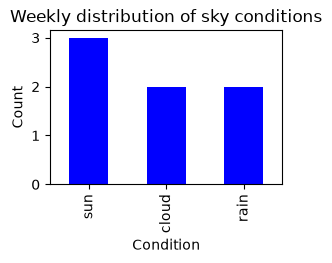

In [20]:
import matplotlib.pyplot as plt

df["sky"].value_counts().plot(kind="bar", color="blue", figsize=(3,2))
plt.xlabel("Condition")
plt.ylabel("Count")
plt.title("Weekly distribution of sky conditions")

In [31]:
df[df["temp"] >= 30].reset_index(drop=True)

,day,temp,rain_mm,sky
0,Tue,31,2.0,cloud
1,Wed,34,0.0,sun
2,Fri,30,1.0,cloud
3,Sun,32,0.0,sun


In [34]:
df["day"].isin(["Mon", "Tue", "Wed"])

0     True
1     True
2     True
3    False
4    False
5    False
6    False
Name: day, dtype: bool

In [36]:
df["temp"].between(29, 31)

0    False
1     True
2    False
3     True
4     True
5    False
6    False
Name: temp, dtype: bool

In [38]:
hottest = df["temp"].idxmax()

In [44]:
df.iloc[2:5, 0:3]

,day,temp,rain_mm
2,Wed,34,0.0
3,Thu,29,5.0
4,Fri,30,1.0


In [45]:
df.loc[df["temp"].idxmax(), "day"]

'Wed'

In [46]:
df["temp"].idxmax()

2

In [47]:
df.loc[df["rain_mm"].idxmax(), "day"]

'Sat'

In [48]:
hot = df[df["temp"] >= 30]
hot.index.tolist()
hot.loc[hot["temp"].idxmax(), "day"]

'Wed'